In [1]:
import joblib

import numpy as np
import pandas as pd

from scipy.stats import loguniform, randint, uniform

from IPython.display import display

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, make_column_selector
from FraudDetection.DataModelling.ModellingTools import RiskLevelEncoder, CustomIsolationForest, ThresholdCostOptimizer


from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, cohen_kappa_score,
    recall_score, precision_score, f1_score, matthews_corrcoef,
    brier_score_loss, roc_auc_score, average_precision_score,
    log_loss, confusion_matrix,
    mean_squared_error, mean_absolute_error, r2_score,
    mean_absolute_percentage_error, mean_pinball_loss
)

In [2]:
%load_ext autoreload
%autoreload 2

# Repertoire de travail

In [3]:
%pwd

'/home/user_daren_mabanza/data_science/projets/V2_projet_fraud_detection/02_notebooks'

In [4]:
%cd "/home/user_daren_mabanza/data_science/projets/V2_projet_fraud_detection"

/home/user_daren_mabanza/data_science/projets/V2_projet_fraud_detection


# Import des données

In [5]:
df = pd.read_parquet("01_data/03_processed_data/FullDataForModel.parquet")
df_copy = df.copy()

In [6]:
df_copy.info()

<class 'pandas.DataFrame'>
RangeIndex: 1852394 entries, 0 to 1852393
Data columns (total 8 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   id                     uint32        
 1   trans_date_trans_time  datetime64[us]
 2   jour                   category      
 3   heure                  int32         
 4   state                  category      
 5   category               category      
 6   amt                    float32       
 7   is_fraud               uint8         
dtypes: category(3), datetime64[us](1), float32(1), int32(1), uint32(1), uint8(1)
memory usage: 42.4 MB


In [7]:
df_copy.sample(5)

,id,trans_date_trans_time,jour,heure,state,category,amt,is_fraud
39012,39013,2020-08-05 08:35:11,Wednesday,8,MI,shopping_pos,3.310000,0
12787,12788,2019-05-26 08:27:51,Sunday,8,PA,shopping_pos,92.110001,0
16691,16692,2019-12-14 09:30:06,Saturday,9,IN,gas_transport,83.510002,0
11821,11822,2019-06-09 18:11:42,Sunday,18,PA,health_fitness,47.740002,0
48753,48754,2019-03-05 13:19:53,Tuesday,13,FL,personal_care,17.879999,0


In [7]:
# Découpage chronologique : train 2019, validation janvier–septembre 2020,
# test octobre–décembre 2020. Les bornes de fin sont exclues.
donnees_modele = df.copy()

donnees_modele["trans_date_trans_time"] = pd.to_datetime(
    donnees_modele["trans_date_trans_time"], errors="raise"
)

donnees_modele = donnees_modele.sort_values("trans_date_trans_time", kind="stable")

masque_train = donnees_modele["trans_date_trans_time"].between("2019-01-01", "2020-01-01", inclusive="left")
masque_validation = donnees_modele["trans_date_trans_time"].between("2020-01-01", "2020-10-01", inclusive="left")
masque_test = donnees_modele["trans_date_trans_time"].between("2020-10-01", "2021-01-01", inclusive="left")

df_train = donnees_modele.loc[masque_train].copy()
df_validation = donnees_modele.loc[masque_validation].copy()
df_test = donnees_modele.loc[masque_test].copy()

# Sélection explicite : aucune cible ni statistique précalculée dans X.
colonnes_entree = ["amt", "heure", "jour", "category", "state"]

X_train = df_train[colonnes_entree].copy()
y_train = df_train["is_fraud"].copy()

X_validation = df_validation[colonnes_entree].copy()
y_validation = df_validation["is_fraud"].copy()

X_test = df_test[colonnes_entree].copy()
y_test = df_test["is_fraud"].copy()


In [195]:
# Prévalence = nombre de fraudes / nombre d'observations × 100.
resume_echantillons = pd.DataFrame([
    {
        "jeu": nom,
        "periode": periode,
        "nb_observations": len(cible),
        "nb_fraudes": int(cible.sum()),
        "prevalence_pct": 100 * cible.mean(),
    }
    for nom, periode, cible in [
        ("train", "2019", y_train),
        ("validation", "janvier–septembre 2020", y_validation),
        ("test", "octobre–décembre 2020", y_test),
    ]
])

display(resume_echantillons.round({"prevalence_pct": 3}))


,jeu,periode,nb_observations,nb_fraudes,prevalence_pct
0,train,2019,924850,5220,0.564
1,validation,janvier–septembre 2020,646023,3495,0.541
2,test,octobre–décembre 2020,281521,936,0.332


In [157]:
X_train.sample(5)

,amt,heure,jour,category,state
24893,75.769997,6,Tuesday,grocery_pos,MI
6059,1.520000,17,Sunday,travel,FL
27025,6.060000,0,Wednesday,misc_pos,AL
6668,48.630001,17,Wednesday,food_dining,OH
14098,440.399994,2,Wednesday,entertainment,MN


# Tests ML

In [23]:
scaler = StandardScaler()

niveaux_risque = ["tres_faible", "faible", "moderee", "elevee"]

risk_level_encoder = RiskLevelEncoder(cv = 5)

one_hot_encoder = OneHotEncoder(
    categories = [niveaux_risque] * 4,
    drop = None,
    sparse_output = False,
    handle_unknown = "error",
)

isolation_forest = CustomIsolationForest(
    n_estimators = 300,
    max_samples = "auto",
    contamination = 0.07,
)

logit = LogisticRegression(
    C = 2.465832945854912,
)

random_forest = RandomForestClassifier(
    max_depth = 17,
    max_features = "sqrt",
    min_samples_leaf = 6,
    min_samples_split = 11,
    n_estimators = 321,
)

xgboost = XGBClassifier(
    colsample_bytree = 0.8736932106048627,
    gamma = 0.010299214204601972,
    learning_rate = 0.014413697528610409,
    max_depth = 8,
    min_child_weight = 4,
    n_estimators = 305,
    reg_alpha = 0.014899847475658236,
    reg_lambda = 0.20399223998555607,
    subsample = 0.902144564127061,
)


# --- Best Params Logit 
# (Stabilité)
    # C = 0.07114476009343425,
    # class_weight={0:1,1:2.1} (a voir si rajouter)
# (Equilibre)
    # C = 2.465832945854912
    # class_weight={0:1,1:2.1} (a voir si rajouter)

# --- Best Params RF
# (Stabilité)
    # max_depth = 7,
    # max_features = 'sqrt',
    # min_samples_leaf = 16,
    # min_samples_split = 45,
    # n_estimators = 314,
    # class_weight={0:1,1:2.1} (a voir si rajouter)
# (Equilibre)
    # max_depth = 17,
    # max_features = sqrt,
    # min_samples_leaf = 6,
    # min_samples_split = 11,
    # n_estimators = 321,

# --- Best Params XGB
# (Stabilité)
    # colsample_bytree = 0.7049790556476374,
    # gamma = 0.10873416514163667,
    # learning_rate = 0.03822770721231413,
    # max_depth = 5,
    # min_child_weight = 5,
    # n_estimators = 99,
    # reg_alpha = 0.45975057847321654,
    # reg_lambda = 2.0497980520950176,
    # subsample = 0.6560204063533432,
    # class_weight={0:1,1:2.1} (a voir si rajouter)
# (Equilibre)
    # colsample_bytree = 0.8736932106048627,
    # gamma = 0.010299214204601972,
    # learning_rate = 0.014413697528610409,
    # max_depth = 8,
    # min_child_weight = 4,
    # n_estimators = 305,
    # reg_alpha = 0.014899847475658236,
    # reg_lambda = 0.20399223998555607,
    # subsample = 0.902144564127061,
    # class_weight={0:1,1:2.1} (a voir si rajouter)

## Pipeline Regression Logistique

In [197]:
encoding = ColumnTransformer(
    transformers = [
        
        ("heure_jour_category_state", risk_level_encoder, ["heure","jour","category","state"]),

    ],  
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")


ohe = ColumnTransformer(
    transformers = [
        
        ("niveaux_risque", one_hot_encoder, make_column_selector(dtype_exclude=np.number)),

    ],  
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")


isolation_forest = ColumnTransformer(
    transformers = [
        
        ("isolation_forest", isolation_forest, make_column_selector(dtype_include=np.number)),
        ("garder_autres_features", "passthrough", make_column_selector(dtype_include=np.number)),
        
    ],
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")


scaler = ColumnTransformer(
    transformers = [
        
        ("scaler", scaler, ["amt","score_anomalie"]),
        
    ],
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")

In [198]:
preprocessing = Pipeline([
    ("encoding_niveaux_risque", encoding),
    
    ("ohe_niveaux_risque", ohe),
    
    ("ajout_feature_score_anomalie", isolation_forest),
    
    ("scaler_score_anomalie_amt", scaler),
    
])

model = Pipeline([
    ("encoding_niveaux_risque", encoding),
    
    ("ohe_niveaux_risque", ohe),
    
    ("ajout_feature_score_anomalie", isolation_forest),
    
    ("scaler_score_anomalie_amt", scaler),
    
    ("model", logit),
    
])

In [ ]:
calibrated_model = CalibratedClassifierCV(
    estimator = model,
    method = "sigmoid",
    cv = 5,
)

In [162]:
hyperparams = {"model__C": loguniform(1e-4, 1e2)}

recherche_model = RandomizedSearchCV(
    estimator=model,
    param_distributions=hyperparams,
    n_iter=10,                
    scoring="neg_log_loss",
    n_jobs=1,
    refit=True,
    cv=5,
    verbose=0,
    random_state=42,
    error_score="raise",
    return_train_score=False,
)

recherche_model.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.",{'model__C': <scipy.stats....x793c7fddb980>}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_log_loss'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``be

In [163]:
model.set_params(**recherche_model.best_params_)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encoding_niveaux_risque', ...), ('ohe_niveaux_risque', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('heure_jour_category_state', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature

In [47]:
preprocessed_X_train = preprocessing.fit_transform(X_train,y_train)
preprocessed_X_train.sample(5)

,amt,score_anomalie,niveau_risque_heure_elevee,niveau_risque_heure_faible,niveau_risque_heure_moderee,niveau_risque_heure_tres_faible,niveau_risque_jour_elevee,niveau_risque_jour_faible,niveau_risque_jour_moderee,niveau_risque_jour_tres_faible,niveau_risque_category_elevee,niveau_risque_category_faible,niveau_risque_category_moderee,niveau_risque_category_tres_faible,niveau_risque_state_elevee,niveau_risque_state_faible,niveau_risque_state_moderee,niveau_risque_state_tres_faible
30495,-0.338731,0.214073,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
42305,-0.415156,0.467910,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
18984,0.392333,-1.070672,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
12635,-0.075227,-0.532850,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
33467,0.054220,-0.373060,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


In [164]:
recherche_model.best_params_

{'model__C': np.float64(2.465832945854912)}

In [199]:
model.fit(X_train, y_train)
#calibrated_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encoding_niveaux_risque', ...), ('ohe_niveaux_risque', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[uint8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['amt','heure','jour','category','state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('heure_jour_category_state', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``,

In [201]:
proba_validation = model.predict_proba(X_validation)[:,1]
#proba_validation = calibrated_model.predict_proba(X_validation)[:,1]

In [202]:
cost_optimizer = ThresholdCostOptimizer(
    cost_fp = 20,
    cost_fn = 125,
    n_thresholds = 200,
)

cost_optimizer.fit(y_validation, proba_validation)

print(f"Seuil optimal : {cost_optimizer.get_best_threshold()}")
print(f"Cout pour le seuil optimal : {cost_optimizer.get_best_cost()}€")

Seuil optimal : 0.06532663316582915
Cout pour le seuil optimal : 265270.0€


In [203]:
proba_train = model.predict_proba(X_train)[:,1]
pred_train = (proba_train > cost_optimizer.get_best_threshold()).astype(int)

proba_validation = model.predict_proba(X_validation)[:,1]
pred_validation = (proba_validation > cost_optimizer.get_best_threshold()).astype(int)

proba_test = model.predict_proba(X_test)[:,1]
pred_test = (proba_test > cost_optimizer.get_best_threshold()).astype(int)

In [204]:
print("ROC AUC (train) :", roc_auc_score(y_train, proba_train))
print("ROC AUC (valid) :", roc_auc_score(y_validation, proba_validation))
print("ROC AUC (test) :", roc_auc_score(y_test, proba_test))
print("---")
print("Précision (train) :", precision_score(y_train, pred_train))
print("Précision (valid) :", precision_score(y_validation, pred_validation))
print("Précision (test) :", precision_score(y_test, pred_test))
print("---")
print("Recall (train) :", recall_score(y_train, pred_train))
print("Recall (valid) :", recall_score(y_validation, pred_validation))
print("Recall (test) :", recall_score(y_test, pred_test))
print("---")
print("Log Loss (train):", log_loss(y_train, np.vstack([1-proba_train, proba_train]).T))
print("Log Loss (valid):", log_loss(y_validation, np.vstack([1-proba_validation, proba_validation]).T))
print("Log Loss (test) :", log_loss(y_test, np.vstack([1-proba_test, proba_test]).T))

ROC AUC (train) : 0.9409984425270483
ROC AUC (valid) : 0.9432164730430679
ROC AUC (test) : 0.9323407585251144
---
Précision (train) : 0.3000540151242348
Précision (valid) : 0.2934682612695492
Précision (test) : 0.1973954763536669
---
Recall (train) : 0.6385057471264368
Recall (valid) : 0.6389127324749643
Recall (test) : 0.6153846153846154
---
Log Loss (train): 0.018727102781261263
Log Loss (valid): 0.01814671173258342
Log Loss (test) : 0.013389527851172346


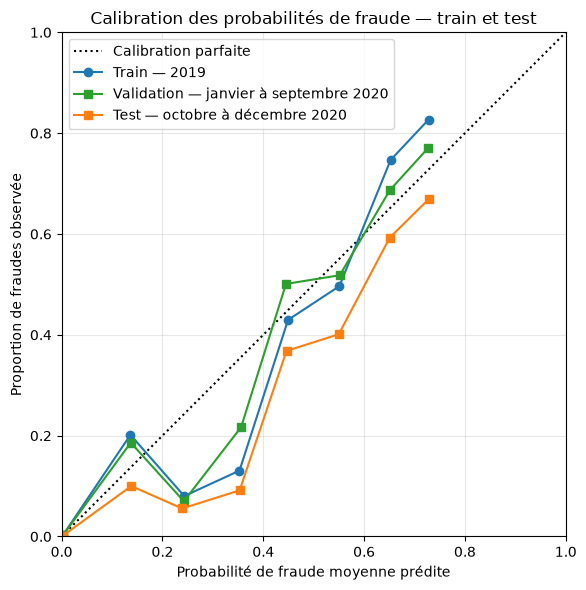

In [205]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

# Même découpage en 10 intervalles de probabilité pour les deux jeux.
# Les intervalles sans observation ne sont pas représentés.
fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_train,
    proba_train,
    n_bins=10,
    strategy="uniform",
    pos_label=1,
    name="Train — 2019",
    ref_line=True,
    ax=ax,
    color="tab:blue",
    marker="o",
)
CalibrationDisplay.from_predictions(
    y_validation,
    proba_validation,
    n_bins=10,
    strategy="uniform",
    pos_label=1,
    name="Validation — janvier à septembre 2020",
    ref_line=False,
    ax=ax,
    color="tab:green",
    marker="s",
)
CalibrationDisplay.from_predictions(
    y_test,
    proba_test,
    n_bins=10,
    strategy="uniform",
    pos_label=1,
    name="Test — octobre à décembre 2020",
    ref_line=False,
    ax=ax,
    color="tab:orange",
    marker="s",
)

# Libellé français de la diagonale de calibration parfaite.
ax.lines[0].set_label("Calibration parfaite")
ax.set(
    title="Calibration des probabilités de fraude — train et test",
    xlabel="Probabilité de fraude moyenne prédite",
    ylabel="Proportion de fraudes observée",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()


In [123]:
def compter_predictions_par_intervalle(y_true, y_pred, probabilites):
    """Compte les bonnes et mauvaises prédictions dans 10 intervalles de probabilité.

    Les trois vecteurs doivent correspondre aux mêmes transactions, dans le
    même ordre. y_true contient les vraies classes ; y_pred contient les
    classes prédites avec le seuil retenu pour le modèle concerné.

    La sortie contient le nombre total de probabilités et les quatre cas :
    Y=0 correct (VN), Y=0 faux (FP), Y=1 correct (VP), Y=1 faux (FN).
    Ces quatre effectifs se somment au total de chaque intervalle.
    Les intervalles sont [0.0, 0.1[, ..., [0.9, 1.0] : 0 et 1 sont inclus.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    probabilites = np.asarray(probabilites)
    if (y_true.ndim != 1 or y_pred.ndim != 1 or probabilites.ndim != 1
            or not (len(y_true) == len(y_pred) == len(probabilites))):
        raise ValueError("Les trois entrées doivent être des vecteurs de même longueur.")
    if not np.isin(y_true, [0, 1]).all() or not np.isin(y_pred, [0, 1]).all():
        raise ValueError("Les classes réelles et prédites doivent valoir 0 ou 1.")
    if not np.isfinite(probabilites).all() or ((probabilites < 0) | (probabilites > 1)).any():
        raise ValueError("Les probabilités doivent être finies et comprises entre 0 et 1.")

    bornes = np.arange(11) / 10
    intervalles = pd.Index(
        [
            f"[{debut:.1f}, {fin:.1f}{']' if i == 9 else '['}"
            for i, (debut, fin) in enumerate(zip(bornes[:-1], bornes[1:]))
        ],
        name="Intervalle de probabilité",
    )
    cas = {
        "VN": (y_true == 0) & (y_pred == 0),
        "FP": (y_true == 0) & (y_pred == 1),
        "VP": (y_true == 1) & (y_pred == 1),
        "FN": (y_true == 1) & (y_pred == 0),
    }
    effectifs = {"Nombre de probas": np.histogram(probabilites, bins=bornes)[0]}
    for nom, masque in cas.items():
        effectifs[nom] = np.histogram(probabilites[masque], bins=bornes)[0]
    return pd.DataFrame(effectifs, index=intervalles)





In [124]:
# Réutilise pred_train : même seuil et mêmes décisions que les métriques ci-dessus.
effectifs_probas_logit = compter_predictions_par_intervalle(
    y_test, pred_test, proba_test
)
display(effectifs_probas_logit)

,Nombre de probas,VN,FP,VP,FN
Intervalle de probabilité,,,,,
"[0.0, 0.1[",279561,278104,999,115,343
"[0.1, 0.2[",867,0,782,85,0
"[0.2, 0.3[",220,0,208,12,0
"[0.3, 0.4[",142,0,136,6,0
"[0.4, 0.5[",216,0,132,84,0
"[0.5, 0.6[",177,0,98,79,0
"[0.6, 0.7[",264,0,98,166,0
"[0.7, 0.8[",74,0,28,46,0
"[0.8, 0.9[",0,0,0,0,0


## Pipeline Random Forest

In [9]:
encoding = ColumnTransformer(
    transformers = [
        
        ("heure_jour_category_state", risk_level_encoder, ["heure","jour","category","state"]),

    ],  
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")


ohe = ColumnTransformer(
    transformers = [
        
        ("niveaux_risque", one_hot_encoder, make_column_selector(dtype_exclude=np.number)),

    ],  
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")


isolation_forest = ColumnTransformer(
    transformers = [
        
        ("isolation_forest", isolation_forest, make_column_selector(dtype_include=np.number)),
        ("garder_autres_features", "passthrough", make_column_selector(dtype_include=np.number)),
        
    ],
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")

In [10]:
preprocessing = Pipeline([
    ("encoding_niveaux_risque", encoding),
    
    ("ohe_niveaux_risque", ohe),
    
    ("ajout_feature_score_anomalie", isolation_forest),
    
])

model = Pipeline([
    ("encoding_niveaux_risque", encoding),
    
    ("ohe_niveaux_risque", ohe),
    
    ("ajout_feature_score_anomalie", isolation_forest),
    
    ("model", random_forest),
    
])

In [178]:
hyperparams = {
    "model__n_estimators": randint(200, 600),
    
    "model__max_depth": randint(10, 25),
    
    "model__min_samples_split": randint(5, 20),
    "model__min_samples_leaf": randint(2, 10),
    
    "model__max_features": ['sqrt', 'log2', 0.5, 0.7],
    
    #"model__class_weight": ['balanced'],
}

recherche_model = RandomizedSearchCV(
    estimator=model,
    param_distributions=hyperparams,
    n_iter=5,                
    scoring="neg_log_loss",
    n_jobs=1,
    refit=True,
    cv=5,
    verbose=0,
    random_state=42,
    error_score="raise",
    return_train_score=False,
)

recherche_model.fit(X_train, y_train)

model.set_params(**recherche_model.best_params_)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encoding_niveaux_risque', ...), ('ohe_niveaux_risque', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('heure_jour_category_state', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature

In [179]:
recherche_model.best_params_

{'model__max_depth': 17,
 'model__max_features': 'sqrt',
 'model__min_samples_leaf': 6,
 'model__min_samples_split': 11,
 'model__n_estimators': 321}

In [180]:
model.set_params(**recherche_model.best_params_)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encoding_niveaux_risque', ...), ('ohe_niveaux_risque', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('heure_jour_category_state', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature

In [20]:
#preprocessing.fit_transform(X_train,y_train)

In [11]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encoding_niveaux_risque', ...), ('ohe_niveaux_risque', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[uint8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['amt','heure','jour','category','state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('heure_jour_category_state', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``,

In [12]:
proba_validation = model.predict_proba(X_validation)[:,1]

In [13]:
cost_optimizer = ThresholdCostOptimizer(
    cost_fp = 20,
    cost_fn = 125,
    n_thresholds = 200,
)

cost_optimizer.fit(y_validation, proba_validation)

print(f"Seuil optimal : {cost_optimizer.get_best_threshold()}")
print(f"Cout pour le seuil optimal : {cost_optimizer.get_best_cost()}€")

Seuil optimal : 0.1658291457286432
Cout pour le seuil optimal : 189675.0€


In [14]:
proba_train = model.predict_proba(X_train)[:,1]
pred_train = (proba_train > cost_optimizer.get_best_threshold()).astype(int)

proba_validation = model.predict_proba(X_validation)[:,1]
pred_validation = (proba_validation > cost_optimizer.get_best_threshold()).astype(int)

proba_test = model.predict_proba(X_test)[:,1]
pred_test = (proba_test > cost_optimizer.get_best_threshold()).astype(int)

In [15]:
print("ROC AUC (train) :", roc_auc_score(y_train, proba_train))
print("ROC AUC (valid) :", roc_auc_score(y_validation, proba_validation))
print("ROC AUC (test) :", roc_auc_score(y_test, proba_test))
print("---")
print("Précision (train) :", precision_score(y_train, pred_train))
print("Précision (valid) :", precision_score(y_validation, pred_validation))
print("Précision (test) :", precision_score(y_test, pred_test))
print("---")
print("Recall (train) :", recall_score(y_train, pred_train))
print("Recall (valid) :", recall_score(y_validation, pred_validation))
print("Recall (test) :", recall_score(y_test, pred_test))
print("---")
print("Log Loss (train):", log_loss(y_train, np.vstack([1-proba_train, proba_train]).T))
print("Log Loss (valid):", log_loss(y_validation, np.vstack([1-proba_validation, proba_validation]).T))
print("Log Loss (test) :", log_loss(y_test, np.vstack([1-proba_test, proba_test]).T))


ROC AUC (train) : 0.9947248974818835
ROC AUC (valid) : 0.9865843996596135
ROC AUC (test) : 0.9806547016619276
---
Précision (train) : 0.5290348964013086
Précision (valid) : 0.47045055588063195
Précision (test) : 0.3684820393974508
---
Recall (train) : 0.7434865900383142
Recall (valid) : 0.6901287553648069
Recall (test) : 0.6794871794871795
---
Log Loss (train): 0.010347325146680492
Log Loss (valid): 0.012880902555082431
Log Loss (test) : 0.009952045682013412


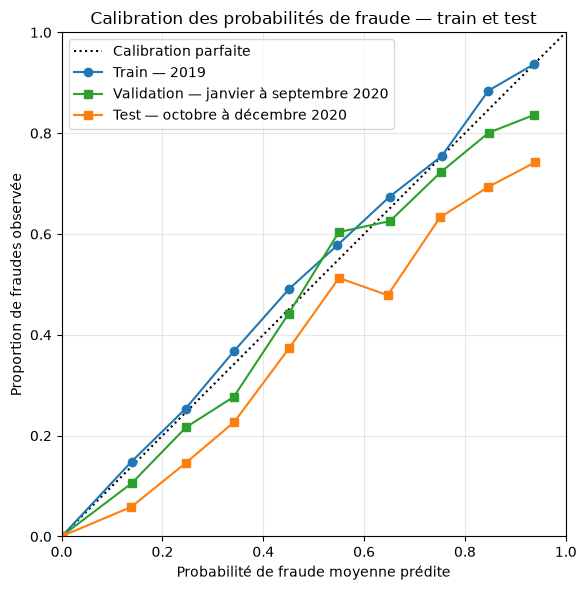

In [16]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

# Même découpage en 10 intervalles de probabilité pour les deux jeux.
# Les intervalles sans observation ne sont pas représentés.
fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_train,
    proba_train,
    n_bins=10,
    strategy="uniform",
    pos_label=1,
    name="Train — 2019",
    ref_line=True,
    ax=ax,
    color="tab:blue",
    marker="o",
)
CalibrationDisplay.from_predictions(
    y_validation,
    proba_validation,
    n_bins=10,
    strategy="uniform",
    pos_label=1,
    name="Validation — janvier à septembre 2020",
    ref_line=False,
    ax=ax,
    color="tab:green",
    marker="s",
)
CalibrationDisplay.from_predictions(
    y_test,
    proba_test,
    n_bins=10,
    strategy="uniform",
    pos_label=1,
    name="Test — octobre à décembre 2020",
    ref_line=False,
    ax=ax,
    color="tab:orange",
    marker="s",
)

# Libellé français de la diagonale de calibration parfaite.
ax.lines[0].set_label("Calibration parfaite")
ax.set(
    title="Calibration des probabilités de fraude — train et test",
    xlabel="Probabilité de fraude moyenne prédite",
    ylabel="Proportion de fraudes observée",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()


In [35]:
# Mémoriser les résultats de Random Forest avant de passer au modèle suivant.
effectifs_probas_random_forest = compter_predictions_par_intervalle(
    y_train, pred_train, proba_train
)
display(effectifs_probas_random_forest)


,Nombre de probas,VN,FP,VP,FN
Intervalle de probabilité,,,,,
"[0.0, 0.1[",913961,912416,0,0,1545
"[0.1, 0.2[",2665,2498,77,16,74
"[0.2, 0.3[",1951,0,1603,348,0
"[0.3, 0.4[",3280,0,2152,1128,0
"[0.4, 0.5[",359,0,217,142,0
"[0.5, 0.6[",385,0,218,167,0
"[0.6, 0.7[",555,0,150,405,0
"[0.7, 0.8[",1694,0,299,1395,0
"[0.8, 0.9[",0,0,0,0,0


In [36]:
# Mémoriser les résultats de Random Forest avant de passer au modèle suivant.
effectifs_probas_random_forest = compter_predictions_par_intervalle(
    y_test, pred_test, proba_test
)
display(effectifs_probas_random_forest)

,Nombre de probas,VN,FP,VP,FN
Intervalle de probabilité,,,,,
"[0.0, 0.1[",278748,278455,0,0,293
"[0.1, 0.2[",772,732,28,1,11
"[0.2, 0.3[",461,0,398,63,0
"[0.3, 0.4[",880,0,682,198,0
"[0.4, 0.5[",106,0,89,17,0
"[0.5, 0.6[",90,0,67,23,0
"[0.6, 0.7[",114,0,38,76,0
"[0.7, 0.8[",350,0,96,254,0
"[0.8, 0.9[",0,0,0,0,0


## Pipeline XGBoost

In [24]:
encoding = ColumnTransformer(
    transformers = [
        
        ("heure_jour_category_state", risk_level_encoder, ["heure","jour","category","state"]),

    ],  
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")


ohe = ColumnTransformer(
    transformers = [
        
        ("niveaux_risque", one_hot_encoder, make_column_selector(dtype_exclude=np.number)),

    ],  
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")


isolation_forest = ColumnTransformer(
    transformers = [
        
        ("isolation_forest", isolation_forest, make_column_selector(dtype_include=np.number)),
        ("garder_autres_features", "passthrough", make_column_selector(dtype_include=np.number)),
        
    ],
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")

In [25]:
preprocessing = Pipeline([
    ("encoding_niveaux_risque", encoding),
    
    ("ohe_niveaux_risque", ohe),
    
    ("ajout_feature_score_anomalie", isolation_forest),
    
])

model = Pipeline([
    ("encoding_niveaux_risque", encoding),
    
    ("ohe_niveaux_risque", ohe),
    
    ("ajout_feature_score_anomalie", isolation_forest),
    
    ("model", xgboost)
    
])

In [190]:
hyperparams = {
    "model__n_estimators": randint(100, 500),
    "model__max_depth": randint(4, 9),
    
    "model__learning_rate": loguniform(0.01, 0.2),
    
    "model__subsample": uniform(0.6, 0.4),        
    "model__colsample_bytree": uniform(0.6, 0.4), 
    
    "model__min_child_weight": randint(2, 7),
    
    "model__gamma": loguniform(1e-3, 0.2), 
    
    "model__reg_alpha": loguniform(1e-3, 1.0),
    "model__reg_lambda": loguniform(0.1, 5.0)
}

recherche_model = RandomizedSearchCV(
    estimator=model,
    param_distributions=hyperparams,
    n_iter=10,                
    scoring="neg_log_loss",
    n_jobs=1,
    refit=True,
    cv=5,
    verbose=0,
    random_state=42,
    error_score="raise",
    return_train_score=False,
)

recherche_model.fit(X_train, y_train)

model.set_params(**recherche_model.best_params_)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encoding_niveaux_risque', ...), ('ohe_niveaux_risque', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('heure_jour_category_state', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature

In [191]:
recherche_model.best_params_

{'model__colsample_bytree': np.float64(0.8736932106048627),
 'model__gamma': np.float64(0.010299214204601972),
 'model__learning_rate': np.float64(0.014413697528610409),
 'model__max_depth': 8,
 'model__min_child_weight': 4,
 'model__n_estimators': 305,
 'model__reg_alpha': np.float64(0.014899847475658236),
 'model__reg_lambda': np.float64(0.20399223998555607),
 'model__subsample': np.float64(0.902144564127061)}

In [26]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('encoding_niveaux_risque', ...), ('ohe_niveaux_risque', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['amt','heure','jour','category','state']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('heure_jour_category_state', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``,

In [27]:
proba_validation = model.predict_proba(X_validation)[:,1]

In [28]:
cost_optimizer = ThresholdCostOptimizer(
    cost_fp = 20,
    cost_fn = 125,
    n_thresholds = 200,
)

cost_optimizer.fit(y_validation, proba_validation)

print(f"Seuil optimal : {cost_optimizer.get_best_threshold()}")
print(f"Cout pour le seuil optimal : {cost_optimizer.get_best_cost()}€")

Seuil optimal : 0.16080402010050251
Cout pour le seuil optimal : 192830.0€


In [37]:
proba_train = model.predict_proba(X_train)[:,1]
pred_train = (proba_train > 0.19).astype(int)

proba_test = model.predict_proba(X_test)[:,1]
pred_test = (proba_test > 0.19).astype(int)

In [38]:
print("ROC AUC (train) :", roc_auc_score(y_train, proba_train))
print("ROC AUC (valid) :", roc_auc_score(y_validation, proba_validation))
print("ROC AUC (test) :", roc_auc_score(y_test, proba_test))
print("---")
print("Précision (train) :", precision_score(y_train, pred_train))
print("Précision (valid) :", precision_score(y_validation, pred_validation))
print("Précision (test) :", precision_score(y_test, pred_test))
print("---")
print("Recall (train) :", recall_score(y_train, pred_train))
print("Recall (valid) :", recall_score(y_validation, pred_validation))
print("Recall (test) :", recall_score(y_test, pred_test))
print("---")
print("Log Loss (train):", log_loss(y_train, np.vstack([1-proba_train, proba_train]).T))
print("Log Loss (valid):", log_loss(y_validation, np.vstack([1-proba_validation, proba_validation]).T))
print("Log Loss (test) :", log_loss(y_test, np.vstack([1-proba_test, proba_test]).T))

ROC AUC (train) : 0.9921284859565584
ROC AUC (valid) : 0.9904693153299831
ROC AUC (test) : 0.9878786712255181
---
Précision (train) : 0.5668202764976958
Précision (valid) : 0.47045055588063195
Précision (test) : 0.4145480225988701
---
Recall (train) : 0.6597701149425287
Recall (valid) : 0.6901287553648069
Recall (test) : 0.6271367521367521
---
Log Loss (train): 0.012005253694951534
Log Loss (valid): 0.012400718405842781
Log Loss (test) : 0.009442988783121109


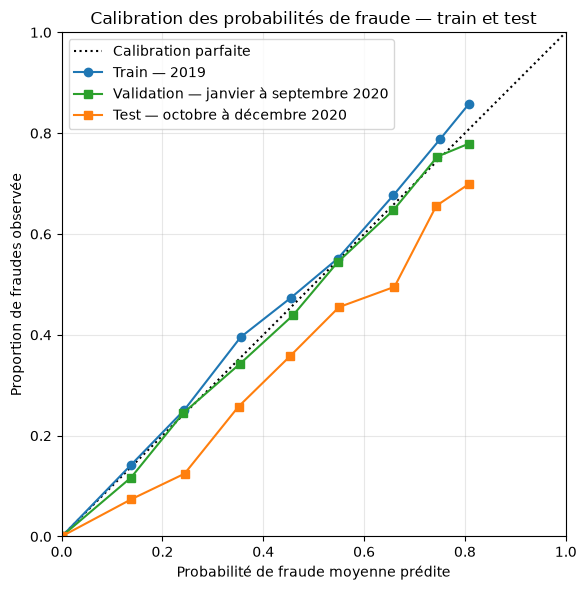

In [34]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

# Même découpage en 10 intervalles de probabilité pour les deux jeux.
# Les intervalles sans observation ne sont pas représentés.
fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_train,
    proba_train,
    n_bins=10,
    strategy="uniform",
    pos_label=1,
    name="Train — 2019",
    ref_line=True,
    ax=ax,
    color="tab:blue",
    marker="o",
)
CalibrationDisplay.from_predictions(
    y_validation,
    proba_validation,
    n_bins=10,
    strategy="uniform",
    pos_label=1,
    name="Validation — janvier à septembre 2020",
    ref_line=False,
    ax=ax,
    color="tab:green",
    marker="s",
)
CalibrationDisplay.from_predictions(
    y_test,
    proba_test,
    n_bins=10,
    strategy="uniform",
    pos_label=1,
    name="Test — octobre à décembre 2020",
    ref_line=False,
    ax=ax,
    color="tab:orange",
    marker="s",
)

# Libellé français de la diagonale de calibration parfaite.
ax.lines[0].set_label("Calibration parfaite")
ax.set(
    title="Calibration des probabilités de fraude — train et test",
    xlabel="Probabilité de fraude moyenne prédite",
    ylabel="Proportion de fraudes observée",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()


In [41]:
effectifs_probas_xgboost = compter_predictions_par_intervalle(
    y_train, pred_train, proba_train
)
display(effectifs_probas_xgboost)


NameError: name 'compter_predictions_par_intervalle' is not defined

In [44]:
joblib.dump(
    value = model,
    filename = "07_artifacts/model_xgboost_V1.joblib",
)

['07_artifacts/model_xgboost_V1.joblib']

# Construction Modelling.py

In [ ]:
df = pd.read_parquet("01_data/03_processed_data/FullDataForModel.parquet")
df_copy = df.copy()

In [ ]:
# Découpage chronologique : train 2019, validation janvier–septembre 2020,
# test octobre–décembre 2020. Les bornes de fin sont exclues.
donnees_modele = df.copy()

donnees_modele["trans_date_trans_time"] = pd.to_datetime(
    donnees_modele["trans_date_trans_time"], errors="raise"
)

donnees_modele = donnees_modele.sort_values("trans_date_trans_time", kind="stable")

masque_train = donnees_modele["trans_date_trans_time"].between("2019-01-01", "2020-01-01", inclusive="left")
masque_validation = donnees_modele["trans_date_trans_time"].between("2020-01-01", "2020-10-01", inclusive="left")
masque_test = donnees_modele["trans_date_trans_time"].between("2020-10-01", "2021-01-01", inclusive="left")

df_train = donnees_modele.loc[masque_train].copy()
df_validation = donnees_modele.loc[masque_validation].copy()
df_test = donnees_modele.loc[masque_test].copy()

# Sélection explicite : aucune cible ni statistique précalculée dans X.
colonnes_entree = ["amt", "heure", "jour", "category", "state"]

X_train = df_train[colonnes_entree].copy()
y_train = df_train["is_fraud"].copy()

X_validation = df_validation[colonnes_entree].copy()
y_validation = df_validation["is_fraud"].copy()

X_test = df_test[colonnes_entree].copy()
y_test = df_test["is_fraud"].copy()


In [ ]:
risk_level_encoder = RiskLevelEncoder(cv = 5)

niveaux_risque = ["tres_faible", "faible", "moderee", "elevee"]
one_hot_encoder = OneHotEncoder(
    categories = [niveaux_risque] * 4,
    drop = None,
    sparse_output = False,
    handle_unknown = "error",
)

isolation_forest = CustomIsolationForest(
    n_estimators = 300,
    max_samples = "auto",
    contamination = 0.07,
)

xgboost = XGBClassifier(
    colsample_bytree = 0.8736932106048627,
    gamma = 0.010299214204601972,
    learning_rate = 0.014413697528610409,
    max_depth = 8,
    min_child_weight = 4,
    n_estimators = 305,
    reg_alpha = 0.014899847475658236,
    reg_lambda = 0.20399223998555607,
    subsample = 0.902144564127061,
)

In [ ]:
encoding = ColumnTransformer(
    transformers = [
        
        ("heure_jour_category_state", risk_level_encoder, ["heure","jour","category","state"]),

    ],  
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")


ohe = ColumnTransformer(
    transformers = [
        
        ("niveaux_risque", one_hot_encoder, make_column_selector(dtype_exclude=np.number)),

    ],  
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")


isolation_forest = ColumnTransformer(
    transformers = [
        
        ("isolation_forest", isolation_forest, make_column_selector(dtype_include=np.number)),
        ("garder_autres_features", "passthrough", make_column_selector(dtype_include=np.number)),
        
    ],
        remainder = "passthrough",
        verbose_feature_names_out = False,
        
).set_output(transform="pandas")

In [ ]:
preprocessing = Pipeline([
    ("encoding_niveaux_risque", encoding),
    
    ("ohe_niveaux_risque", ohe),
    
    ("ajout_feature_score_anomalie", isolation_forest),
    
])

model = Pipeline([
    ("encoding_niveaux_risque", encoding),
    
    ("ohe_niveaux_risque", ohe),
    
    ("ajout_feature_score_anomalie", isolation_forest),
    
    ("model", xgboost)
    
])

In [ ]:
model.fit(X_train, y_train)

In [ ]:
proba_validation = model.predict_proba(X_validation)[:,1]

In [ ]:
cost_optimizer = ThresholdCostOptimizer(
    cost_fp = 20,
    cost_fn = 125,
    n_thresholds = 200,
)

cost_optimizer.fit(y_validation, proba_validation)

print(f"Seuil optimal : {cost_optimizer.get_best_threshold()}")
print(f"Cout pour le seuil optimal : {cost_optimizer.get_best_cost()}€")

In [ ]:
proba_train = model.predict_proba(X_train)[:,1]
pred_train = (proba_train > cost_optimizer.get_best_threshold()).astype(int)

proba_validation = model.predict_proba(X_validation)[:,1]
pred_validation = (proba_validation > cost_optimizer.get_best_threshold()).astype(int)

proba_test = model.predict_proba(X_test)[:,1]
pred_test = (proba_test > cost_optimizer.get_best_threshold()).astype(int)

In [ ]:
print("ROC AUC (train) :", roc_auc_score(y_train, proba_train))
print("ROC AUC (valid) :", roc_auc_score(y_validation, proba_validation))
print("ROC AUC (test) :", roc_auc_score(y_test, proba_test))
print("---")
print("Précision (train) :", precision_score(y_train, pred_train))
print("Précision (valid) :", precision_score(y_validation, pred_validation))
print("Précision (test) :", precision_score(y_test, pred_test))
print("---")
print("Recall (train) :", recall_score(y_train, pred_train))
print("Recall (valid) :", recall_score(y_validation, pred_validation))
print("Recall (test) :", recall_score(y_test, pred_test))
print("---")
print("Log Loss (train):", log_loss(y_train, np.vstack([1-proba_train, proba_train]).T))
print("Log Loss (valid):", log_loss(y_validation, np.vstack([1-proba_validation, proba_validation]).T))
print("Log Loss (test) :", log_loss(y_test, np.vstack([1-proba_test, proba_test]).T))

In [ ]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

# Même découpage en 10 intervalles de probabilité pour les deux jeux.
# Les intervalles sans observation ne sont pas représentés.
fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(
    y_train,
    proba_train,
    n_bins=10,
    strategy="uniform",
    pos_label=1,
    name="Train — 2019",
    ref_line=True,
    ax=ax,
    color="tab:blue",
    marker="o",
)
CalibrationDisplay.from_predictions(
    y_validation,
    proba_validation,
    n_bins=10,
    strategy="uniform",
    pos_label=1,
    name="Validation — janvier à septembre 2020",
    ref_line=False,
    ax=ax,
    color="tab:green",
    marker="s",
)
CalibrationDisplay.from_predictions(
    y_test,
    proba_test,
    n_bins=10,
    strategy="uniform",
    pos_label=1,
    name="Test — octobre à décembre 2020",
    ref_line=False,
    ax=ax,
    color="tab:orange",
    marker="s",
)

# Libellé français de la diagonale de calibration parfaite.
ax.lines[0].set_label("Calibration parfaite")
ax.set(
    title="Calibration des probabilités de fraude — train et test",
    xlabel="Probabilité de fraude moyenne prédite",
    ylabel="Proportion de fraudes observée",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.set_aspect("equal", adjustable="box")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()


# Test Modelling.py

In [51]:
import yaml
import joblib

import numpy as np
import pandas as pd

from time import perf_counter

from FraudDetection.DataModelling.ModellingParameters import (
    risk_level_encoder, one_hot_encoder, custom_isolation_forest,
    xgboost, threshold_cost_optimizer
)

from FraudDetection.DataModelling.ModellingTools import (
    display_roc_auc_score, display_precision_score,
    display_recall_score, display_log_loss
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, make_column_selector

In [41]:
# 0. Import des configurations
config = yaml.safe_load(open("11_configs/paths.yaml"))
echantillon = config["echantillon"]["type"]
    
print("step_3_modelling - 0. Import des configurations - OK")

step_3_modelling - 0. Import des configurations - OK


In [42]:
    # 1. Import des données 
try:
    df = pd.read_parquet(f"01_data/03_processed_data/{echantillon}DataForModel.parquet")
    df_copy = df.copy()
    print("step_3_modelling - 1. Import des données - OK")
        
except FileNotFoundError:
    raise FileNotFoundError("step_3_modelling - 1. Import des données - Le fichier est introuvable")

step_3_modelling - 1. Import des données - OK


In [43]:
    # 2. Découpage chronologique et construction des échantillons (Train - Validation - Test)
        # Train : 2019
        # Validation : janvier–septembre 2020
        # Test : octobre–décembre 2020
        
df_copy["trans_date_trans_time"] = pd.to_datetime(df_copy["trans_date_trans_time"], errors="raise")
df_copy = df_copy.sort_values("trans_date_trans_time", kind="stable")
    
masque_train = df_copy["trans_date_trans_time"].between("2019-01-01", "2020-01-01", inclusive="left")
masque_validation = df_copy["trans_date_trans_time"].between("2020-01-01", "2020-10-01", inclusive="left")
masque_test = df_copy["trans_date_trans_time"].between("2020-10-01", "2021-01-01", inclusive="left")
    
df_train = df_copy.loc[masque_train].copy()
df_validation = df_copy.loc[masque_validation].copy()
df_test = df_copy.loc[masque_test].copy()
    
colonnes_entree = ["amt", "heure", "jour", "category", "state"]

X_train = df_train[colonnes_entree].copy()
y_train = df_train["is_fraud"].copy()

X_validation = df_validation[colonnes_entree].copy()
y_validation = df_validation["is_fraud"].copy()

X_test = df_test[colonnes_entree].copy()
y_test = df_test["is_fraud"].copy()
    
print("step_3_modelling - 3. Découpage chronologique et construction des échantillons - OK")

step_3_modelling - 3. Découpage chronologique et construction des échantillons - OK


In [44]:
    # 4. Controle minimal de la qualité des données 
        # TODO : Mettre en place une méthode de validation des données plus robuste avec Great Expectations
        
if (len(list(X_train.columns)) == 5) & (sorted(colonnes_entree) == sorted(list(X_train.columns))):
    print("step_3_modelling - 4. Controle minimal de la qualité des données - 5 features : OK")
            
else:
    raise ValueError("ERREUR : Les données ne correspondent pas à ce qui est attendu")

step_3_modelling - 4. Controle minimal de la qualité des données - 5 features : OK


In [45]:
# 5. Création du pipeline    

encoding = ColumnTransformer(
    transformers = [
        ("heure_jour_category_state", risk_level_encoder(), ["heure","jour","category","state"]),
        ],  
            remainder = "passthrough",
            verbose_feature_names_out = False,
    
).set_output(transform="pandas")


ohe = ColumnTransformer(
    transformers = [
        ("niveaux_risque", one_hot_encoder(), make_column_selector(dtype_exclude=np.number)),
    ],  
        remainder = "passthrough",
        verbose_feature_names_out = False,
    
).set_output(transform="pandas")


isolation_forest = ColumnTransformer(
transformers = [
    ("isolation_forest", custom_isolation_forest(), make_column_selector(dtype_include=np.number)),
    ("garder_autres_features", "passthrough", make_column_selector(dtype_include=np.number)),
    ],
        remainder = "passthrough",
        verbose_feature_names_out = False,
    
).set_output(transform="pandas")

print("step_3_modelling - 5. Création du pipeline : OK")

step_3_modelling - 5. Création du pipeline : OK


In [46]:
preprocessing = Pipeline([
("encoding_niveaux_risque", encoding),

("ohe_niveaux_risque", ohe),

("ajout_feature_score_anomalie", isolation_forest),

])

debut_preprocessing = perf_counter()
X_train_preprocessing = preprocessing.fit_transform(X_train, y_train)
temps_preprocessing = perf_counter() - debut_preprocessing

print(
    "step_3_modelling - 6. Preprocessing des données d'entraînement "
    f"(temps de preprocessing : {temps_preprocessing:.3f} s) : OK"
)

step_3_modelling - 6. Preprocessing des données d'entraînement (temps de preprocessing : 64.979 s) : OK


In [47]:
# 7. Controle minimal de la qualité des données 
    # TODO : Mettre en place une méthode de validation des données plus robuste avec Great Expectations
    
if (len(list(X_train_preprocessing.columns)) == 18):
    print("step_3_modelling - 7. Controle minimal de la qualité des données - 18 features : OK")
        
else:
    raise ValueError("ERREUR : Les données ne correspondent pas à ce qui est attendu")

step_3_modelling - 7. Controle minimal de la qualité des données - 18 features : OK


In [48]:
# 8. Entrainement du modèle

model = Pipeline([
("encoding_niveaux_risque", encoding),
("ohe_niveaux_risque", ohe),
("ajout_feature_score_anomalie", isolation_forest),
("model", xgboost()),
])

# Les transformateurs du pipeline ont déjà été ajustés à l'étape 6.
# Entraîner uniquement le classifieur pour mesurer son temps de fit seul.
debut_fit = perf_counter()
model.named_steps["model"].fit(X_train_preprocessing, y_train)
temps_fit = perf_counter() - debut_fit

print(
    "step_3_modelling - 8. Entraînement du modèle "
    f"(temps de fit : {temps_fit:.3f} s) : OK"
)

step_3_modelling - 8. Entraînement du modèle (temps de fit : 42.919 s) : OK


In [ ]:
# 9. Recherche du seuil optimal sur l'échantillon de validation

cost_optimizer = threshold_cost_optimizer()

proba_validation = model.predict_proba(X_validation)[:,1]

cost_optimizer.fit(y_validation, proba_validation)

print(f"Seuil optimal : {cost_optimizer.get_best_threshold()}")
print(f"Cout pour le seuil optimal : {cost_optimizer.get_best_cost()}€")

print("step_3_modelling - 9. Recherche du seuil optimal sur l'échantillon de validation : OK")

Seuil optimal : 0.16080402010050251
Cout pour le seuil optimal : 192830.0€
step_3_modelling - 9. Recherche du seuil optimal sur l'échantillon de validation : OK


In [50]:
# 10. Calcul des probabilités et prédictions

proba_train = model.predict_proba(X_train)[:,1]
pred_train = (proba_train > cost_optimizer.get_best_threshold()).astype(int)

pred_validation = (proba_validation > cost_optimizer.get_best_threshold()).astype(int)

proba_test = model.predict_proba(X_test)[:,1]
pred_test = (proba_test > cost_optimizer.get_best_threshold()).astype(int)

print("step_3_modelling - 10. Calcul des probabilités et prédictions : OK")

step_3_modelling - 10. Calcul des probabilités et prédictions : OK


In [52]:
# 11. Affichage des métriques

display_roc_auc_score(y_train,proba_train,
                        y_validation,proba_validation,
                        y_test,proba_test)

display_precision_score(y_train,pred_train,
                        y_validation,pred_validation,
                        y_test,pred_test)

display_recall_score(y_train,pred_train,
                    y_validation,pred_validation,
                    y_test,pred_test)

display_log_loss(y_train,proba_train,
                y_validation,proba_validation,
                y_test,proba_test)

print("step_3_modelling - Affichage des métriques : OK")

ROC AUC (train) : 0.9921284859565584
ROC AUC (valid) : 0.9904693153299831
ROC AUC (test) : 0.9878786712255181
---
Précision (train) : 0.5193362193362193
Précision (valid) : 0.49077568134171906
Précision (test)  : 0.37279902853673347
---
Rappel (train) : 0.689463601532567
Rappel (valid) : 0.6698140200286123
Rappel (test)  : 0.655982905982906
---
Log Loss (train) : 0.012005253694951534
Log Loss (valid) : 0.012400718405842781
Log Loss (test)  : 0.009442988783121109
---
step_3_modelling - Affichage des métriques : OK


In [37]:
# 12. Export du modèle

joblib.dump(
    value = model,
    filename = f"07_artifacts/{echantillon}XGBoostModel_V1.joblib",
)   

print("step_3_modelling - Export du modèle : OK")


step_3_modelling - Export du modèle : OK
